<a href="https://colab.research.google.com/github/Haritsukeru/Machine-Learn/blob/main/Copy_of_%D0%9B%D0%A05_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [2]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [5]:
# Зчитайте датасет у DataFrame та перегляньте дані
import pandas as pd

csv_path = f"{path}/kaggel_weather_2013_to_2024.csv"
df = pd.read_csv(csv_path)

print(df.head())
print(df.info())
print(df.describe())

   Unnamed: 0       DATE  tempmax  tempmin  temp  feelslikemax  feelslikemin  \
0           0  4/14/2013     37.7     23.1  28.7          35.4          23.1   
1           1  4/15/2013     37.5     21.1  28.6          35.3          21.1   
2           2  4/16/2013     40.1     21.9  31.7          37.5          21.9   
3           3  4/17/2013     36.4     21.0  29.9          34.0          21.0   
4           4  4/18/2013     37.5     21.7  30.6          35.2          21.7   

   feelslike  humidity  precip  ...  year-2000  weekofyear  tempmax_humidity  \
0       28.1      39.7     2.0  ...         13          15           1496.69   
1       28.0      41.7     0.0  ...         13          16           1563.75   
2       30.4      30.7     0.0  ...         13          16           1231.07   
3       28.5      27.4     0.0  ...         13          16            997.36   
4       29.2      23.7     0.0  ...         13          16            888.75   

   tempmin_humidity temp_humidity  fee

Підготовка даних

In [9]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df = df.reset_index()

date_col = [col for col in df.columns if 'date' in col.lower()][0]
target_col = [col for col in df.columns if 'temp' in col.lower()][0]

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col)

df = df.drop_duplicates(subset=[date_col])

df.set_index(date_col, inplace=True)
df = df.asfreq('D')

print(df.isnull().sum())
df = df.ffill()


index                    693
Unnamed: 0               693
tempmax                  693
tempmin                  693
temp                     693
feelslikemax             693
feelslikemin             693
feelslike                693
humidity                 693
precip                   693
precipprob               693
precipcover              693
windspeed                693
sealevelpressure         693
conditions               693
Year                     693
month                    693
dayofweek                693
dayofyear                693
year-2000                693
weekofyear               693
tempmax_humidity         693
tempmin_humidity         693
temp_humidity            693
feelslikemax_humidity    693
feelslikemin_humidity    693
feelslike_humidity       693
temp_range               693
heat_index               693
dtype: int64


In [ ]:
# Перегляньте інформацію про структуру датасету
#  ^^^^^^ <3

In [ ]:
# Перевірте наявність пропущених значень
#  ^^^^^^ <3

Графік температури

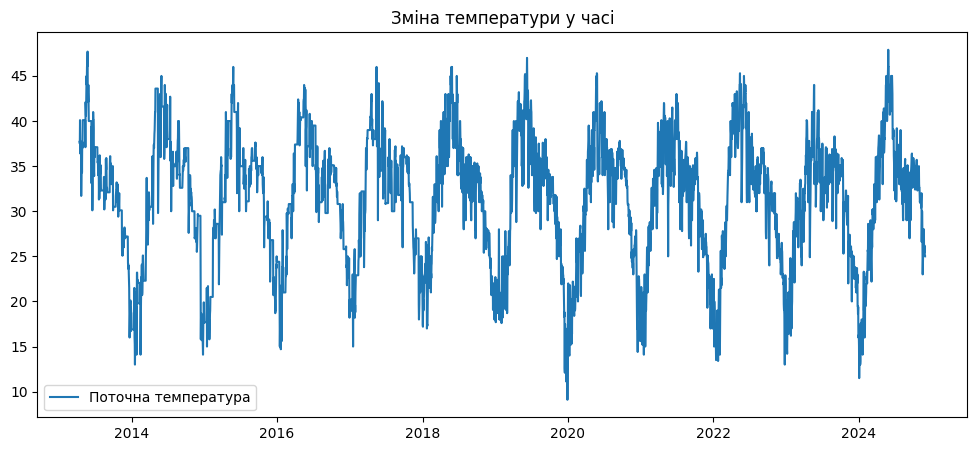

In [15]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(12, 5))
plt.plot(df[target_col], label='Поточна температура')
plt.title('Зміна температури у часі')
plt.legend()
plt.show()


Ковзне середнє

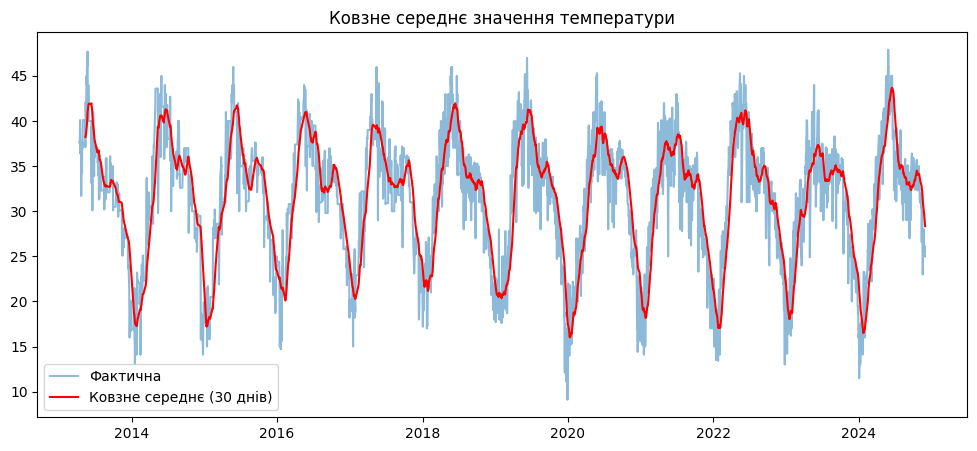

In [14]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['moving_avg'] = df[target_col].rolling(window=30).mean()
plt.figure(figsize=(12, 5))
plt.plot(df[target_col], alpha=0.5, label='Фактична')
plt.plot(df['moving_avg'], color='red', label='Ковзне середнє (30 днів)')
plt.title('Ковзне середнє значення температури')
plt.legend()
plt.show()


Розподіл температури

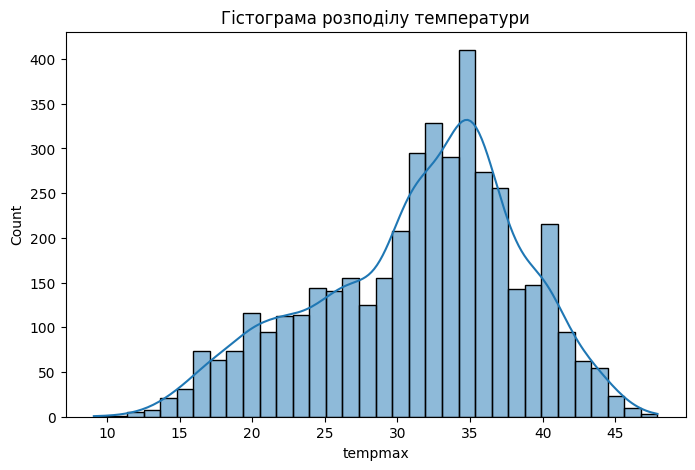

In [13]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
sns.histplot(df[target_col], kde=True)
plt.title('Гістограма розподілу температури')
plt.show()


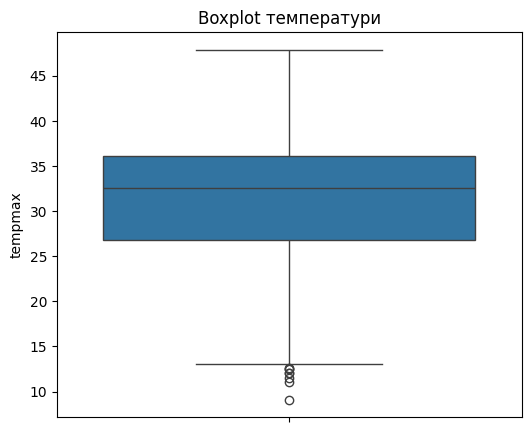

In [12]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(6, 5))
sns.boxplot(y=df[target_col])
plt.title('Boxplot температури')
plt.show()


Аналіз автокореляції
ACF

PACF

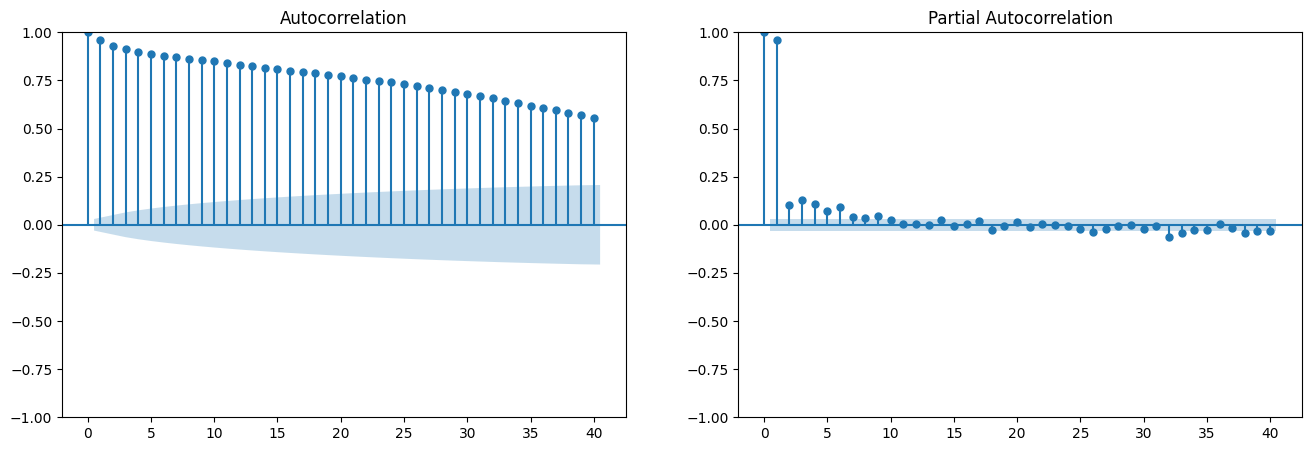

In [16]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(df[target_col].squeeze(), ax=ax[0], lags=40)
plot_pacf(df[target_col].squeeze(), ax=ax[1], lags=40)
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

In [ ]:
# Побудуйте графік часткової автокореляційної функції (PACF)
#  ^^^^^^ <3

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [17]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
series = df[target_col]
train_size = int(len(series) * 0.8)
train, test = series.iloc[:train_size], series.iloc[train_size:]

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [18]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train, order=(5, 1, 0))
arima_result = arima_model.fit()
print(arima_result.summary())

arima_pred = arima_result.forecast(steps=len(test))
arima_pred.index = test.index


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6971.050
Date:                Mon, 09 Nov 2026   AIC                          13954.100
Time:                        22:34:35   BIC                          13990.886
Sample:                    04-14-2013   HQIC                         13967.248
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1674      0.013    -12.925      0.000      -0.193      -0.142
ar.L2         -0.1901      0.016    -12.242      0.000      -0.221      -0.160
ar.L3         -0.1471      0.017     -8.663      0.0

count    3399.000000
mean        0.009063
std         1.990441
min       -13.800000
25%        -0.663425
50%         0.000000
75%         1.018039
max        37.700000
dtype: float64


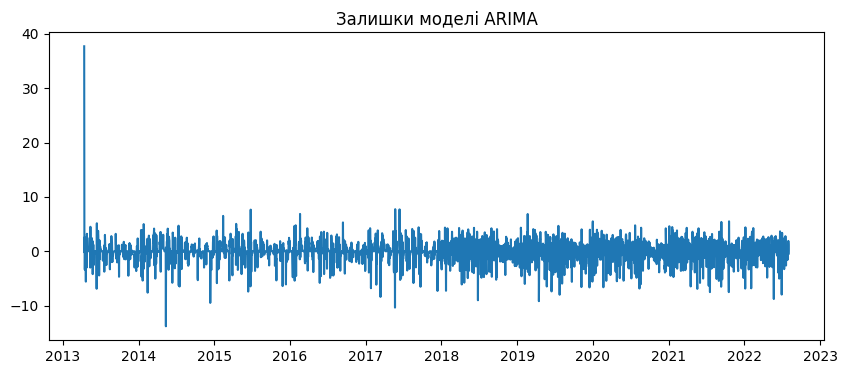

In [19]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.resid.describe())
plt.figure(figsize=(10, 4))
plt.plot(arima_result.resid)
plt.title('Залишки моделі ARIMA')
plt.show()


сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

In [22]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
#  ^^^^^^ <3

In [20]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
arima_mae, arima_rmse, arima_mape = calculate_metrics(test, arima_pred)


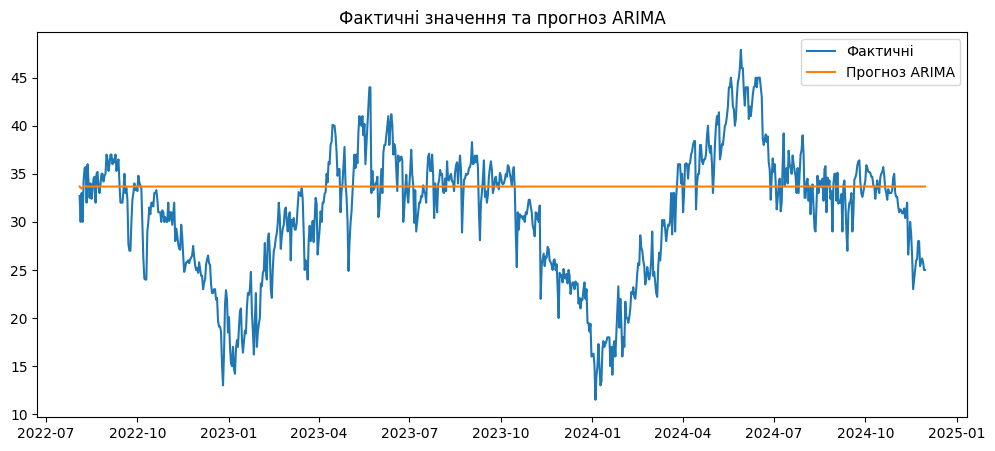

In [21]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label='Фактичні')
plt.plot(test.index, arima_pred, label='Прогноз ARIMA')
plt.title('Фактичні значення та прогноз ARIMA')
plt.legend()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [23]:
# Підготуйте дані у форматі, необхідному для Prophet
df_prophet = train.reset_index().rename(columns={date_col: 'ds', target_col: 'y'})
prophet_model = Prophet()
prophet_model.fit(df_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [24]:
# Створіть та навчіть модель Prophet
#  ^^^^^^ <3

Прогноз

In [25]:
# Побудуйте прогноз Prophet для тестового періоду
future = prophet_model.make_future_dataframe(periods=len(test), freq='D')
forecast = prophet_model.predict(future)
prophet_pred = forecast.set_index('ds').loc[test.index, 'yhat']


In [26]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae, prophet_rmse, prophet_mape = calculate_metrics(test, prophet_pred)


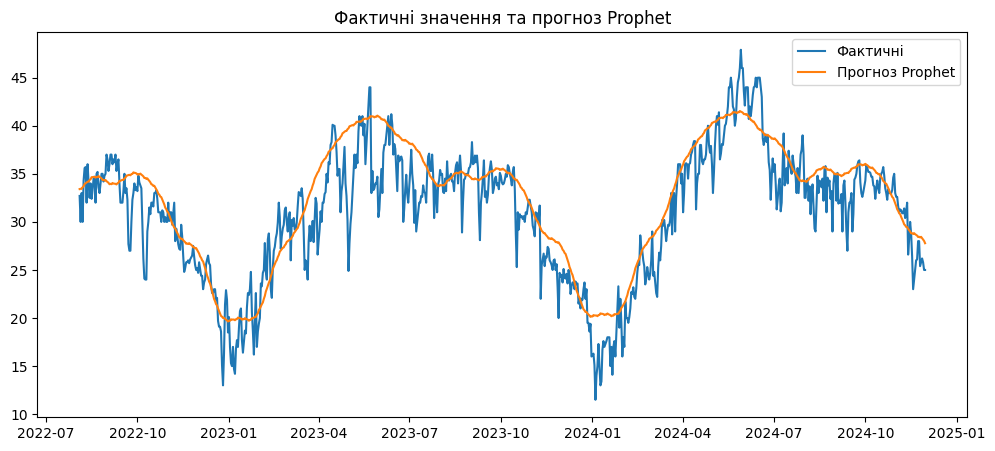

In [27]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label='Фактичні')
plt.plot(test.index, prophet_pred, label='Прогноз Prophet')
plt.title('Фактичні значення та прогноз Prophet')
plt.legend()
plt.show()


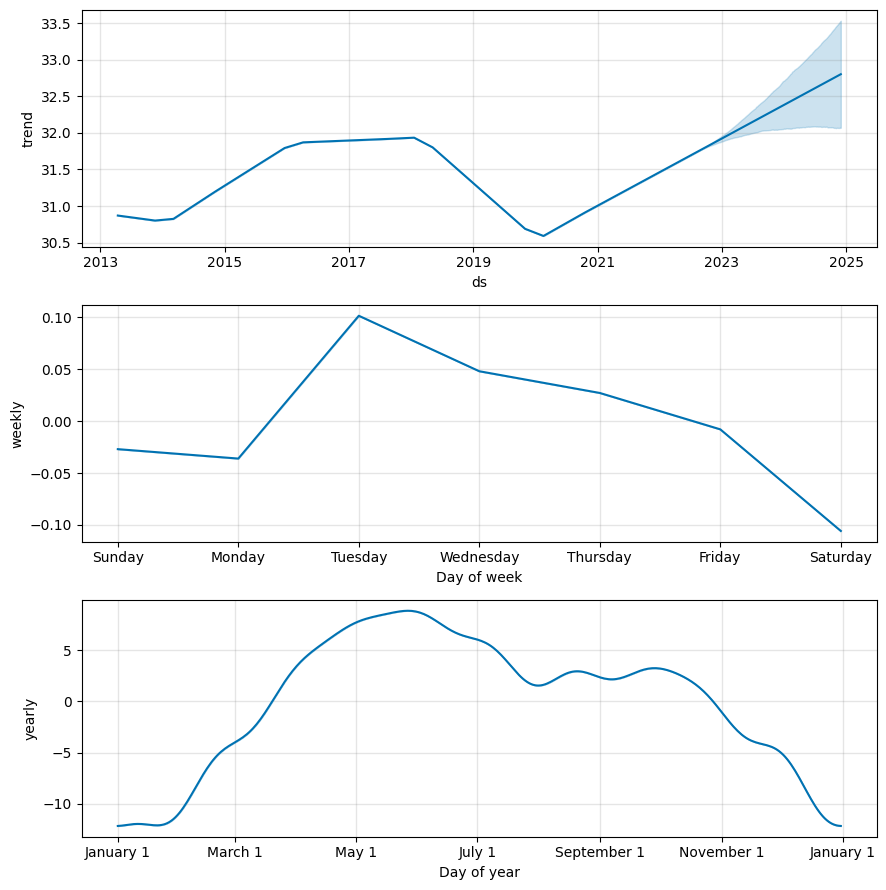

In [28]:
# Побудуйте компоненти моделі Prophet
prophet_model.plot_components(forecast)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [29]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train.values.reshape(-1, 1))
scaled_test = scaler.transform(test.values.reshape(-1, 1))

def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X_train, y_train = create_sequences(scaled_train, seq_length)


In [30]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
lstm_train_size = int(len(X_train) * 0.8)
X_train_lstm, X_val_lstm = X_train[:lstm_train_size], X_train[lstm_train_size:]
y_train_lstm, y_val_lstm = y_train[:lstm_train_size], y_train[lstm_train_size:]


In [31]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_length, 1)),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0308
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0042
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0039
Epoch 4/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0036
Epoch 5/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0035
Epoch 6/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0033
Epoch 7/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0032
Epoch 8/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031
Epoch 9/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0030
Epoch 10/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0029


In [32]:
# Навчіть LSTM-модель
#  ^^^^^^ <3

In [33]:
# Виведіть структуру LSTM-моделі
print(lstm_model.summary())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

None


In [34]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
inputs = np.concatenate((scaled_train[-seq_length:], scaled_test), axis=0)
X_test, _ = create_sequences(inputs, seq_length)
lstm_scaled_pred = lstm_model.predict(X_test)
lstm_pred = scaler.inverse_transform(lstm_scaled_pred).flatten()


27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


In [35]:
# Сформуйте часові мітки для тестового прогнозу LSTM
#  ^^^^^^ <3

In [36]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae, lstm_rmse, lstm_mape = calculate_metrics(test, lstm_pred)


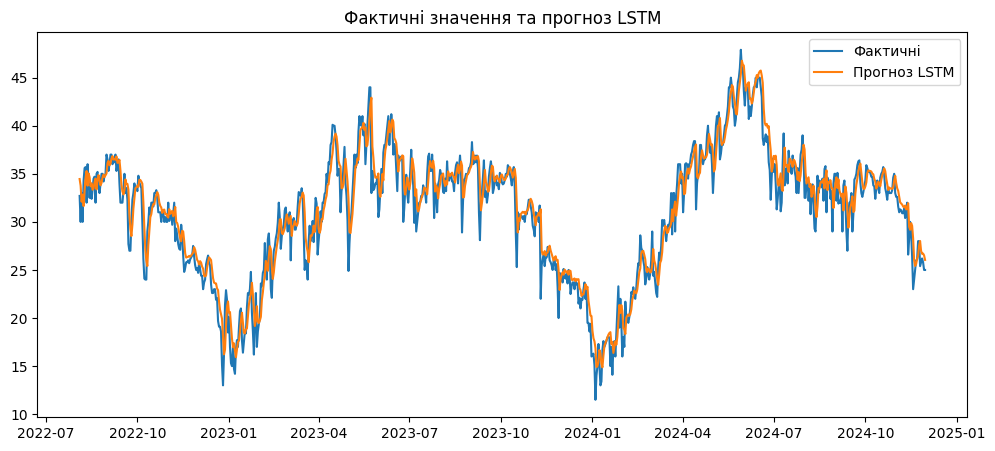

In [37]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label='Фактичні')
plt.plot(test.index, lstm_pred, label='Прогноз LSTM')
plt.title('Фактичні значення та прогноз LSTM')
plt.legend()
plt.show()


Порівняння моделей

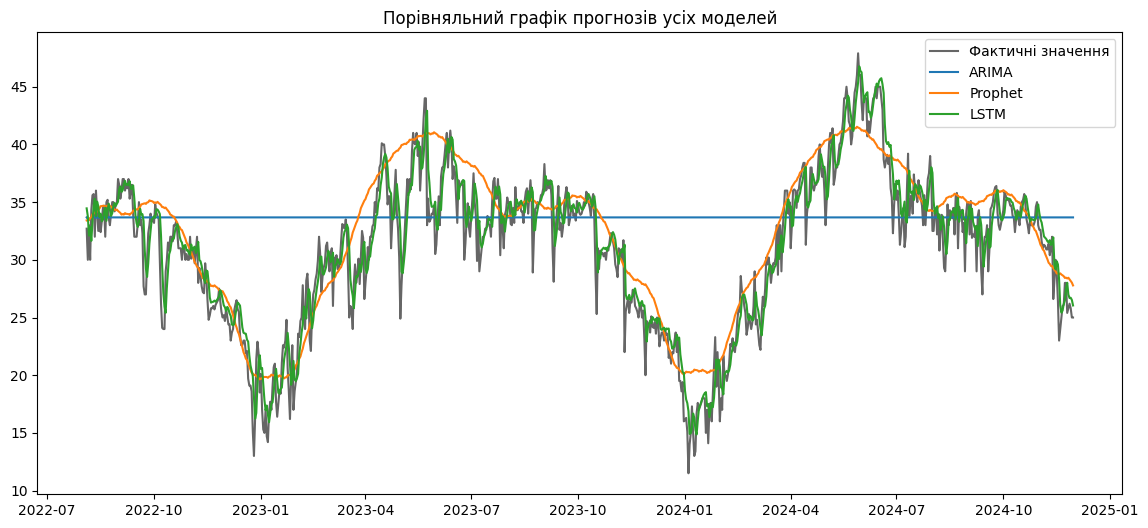

     Model       MAE      RMSE   MAPE (%)
0    ARIMA  5.251711  7.116873  21.622173
1  Prophet  2.445420  3.213511   8.812863
2     LSTM  1.496735  2.005877   5.344017
Найкраща модель за метрикою RMSE: LSTM


In [38]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
plt.figure(figsize=(14, 6))
plt.plot(test.index, test, label='Фактичні значення', color='black', alpha=0.6)
plt.plot(test.index, arima_pred, label='ARIMA')
plt.plot(test.index, prophet_pred, label='Prophet')
plt.plot(test.index, lstm_pred, label='LSTM')
plt.title('Порівняльний графік прогнозів усіх моделей')
plt.legend()
plt.show()

metrics_table = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [arima_mae, prophet_mae, lstm_mae],
    'RMSE': [arima_rmse, prophet_rmse, lstm_rmse],
    'MAPE (%)': [arima_mape, prophet_mape, lstm_mape]
})
print(metrics_table)

best_model = metrics_table.loc[metrics_table['RMSE'].idxmin()]['Model']
print(f"Найкраща модель за метрикою RMSE: {best_model}")


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході лабораторної роботи було виконано повний цикл аналізу часового ряду щоденної температури. Дослідницький аналіз даних (EDA) за допомогою графіків ковзного середнього, гістограм та boxplot дозволив виявити чітку сезонність часового ряду без аномальних викидів, що також підтвердилося стійким згасанням на графіку автокореляційної функції (ACF).
Для прогнозування температури на тестовій вибірці (20% від загального обсягу даних) було побудовано та навчено три моделі: класичну статистичну модель ARIMA, модель декомпозиції часових рядів Prophet від Meta та нейронну мережу LSTM (з використанням бібліотеки TensorFlow/Keras). Оцінка якості моделей проводилася за метриками MAE, RMSE та MAPE.
За сукупністю метрик MAE та RMSE найкращу якість прогнозування продемонструвала модель LSTM, що робить її найбільш оптимальним вибором для цього типу кліматичних даних.